# **Anomaly Detection & Time Series | Assignment (DA-AG-018)**

# **THEORY QUESTION**

### **1. What is Anomaly Detection? Explain its types (point, contextual, and collective anomalies) with examples.**

**Answer**:

**Anomaly Detection** (outlier detection) is the process of identifying observations, events or patterns that deviate significantly from the expected or normal behaviour of a dataset. Anomalies are rare, but they usually point to important events such as fraud, equipment failure, network intrusion, data-entry errors or medical emergencies.

🔹 **Types of anomalies**

**1. Point anomaly**: A single data point that is abnormal compared to the rest of the data.
*Example*: A credit card transaction of Rs. 5,00,000 when the customer usually spends Rs. 500 to Rs. 5,000.

**2. Contextual (conditional) anomaly**: A data point that is abnormal only in a specific context (time, location, season), though it may be normal elsewhere.
*Example*: 30°C is normal in summer but anomalous in January in Shimla; high electricity use at 3 AM in an office building.

**3. Collective anomaly**: A group of related data points that is abnormal together, even if each point looks normal on its own.
*Example*: A flat-line in an ECG for several seconds; many small bank withdrawals within a few minutes (coordinated attack); a sustained burst of packets in a DDoS attack.

### **2. Compare Isolation Forest, DBSCAN, and Local Outlier Factor in terms of their approach and suitable use cases.**

**Answer**:

| Aspect | Isolation Forest | DBSCAN | Local Outlier Factor (LOF) |
|---|---|---|---|
| **Approach** | Builds random trees with random splits. Anomalies are few and different, so they get isolated in fewer splits (short path length). | Density-based clustering. Points having at least `min_samples` neighbours within radius `eps` form clusters; points in no cluster are noise (outliers). | Compares the local density of a point with the density of its k nearest neighbours. LOF score much greater than 1 means the point lies in a sparser area than its neighbours. |
| **Type** | Ensemble, tree-based, global | Clustering, density-based | Density-based, local |
| **Key parameters** | `n_estimators`, `contamination` | `eps`, `min_samples` | `n_neighbors`, `contamination` |
| **Strengths** | Fast (linear time), scales to large and high-dimensional data, no distance computation | Finds arbitrary-shaped clusters, no need to give number of clusters, marks noise automatically | Detects local outliers when clusters have different densities |
| **Weaknesses** | Weak for local anomalies inside dense regions | Sensitive to `eps`; poor with varying densities and high dimensions | Slow on big data (O(n²)); sensitive to k; needs scaling |
| **Use cases** | Fraud detection, server log monitoring, large tabular and sensor data | Geospatial (GPS) data, customer segmentation with noise | Fine-grained local anomalies, e.g. a slightly unusual transaction inside a dense normal group, network intrusion |

### **3. What are the key components of a Time Series? Explain each with one example.**

**Answer**:

A time series is a sequence of observations recorded over time. It has four components:

**1. Trend (T)**: Long-term upward or downward movement. *Example*: Airline passengers rising steadily from 1949 to 1960.

**2. Seasonality (S)**: Regular repeating pattern at a fixed period (daily, weekly, monthly, yearly). *Example*: Ice-cream sales peak every summer; airline traffic peaks every July/August.

**3. Cyclic component (C)**: Rises and falls over irregular, longer periods (usually more than a year) linked to economic or business cycles. *Example*: Real-estate prices going through boom and recession cycles.

**4. Irregular / Residual / Noise (R)**: Random, unpredictable fluctuations left after removing the other components. *Example*: A sudden dip in sales due to a strike or natural disaster.

🔹 **Models**: **Additive**: `Y = T + S + C + R` (constant seasonal amplitude). **Multiplicative**: `Y = T × S × C × R` (seasonal amplitude grows with the level).

### **4. Define Stationary in time series. How can you test and transform a non-stationary series into a stationary one?**

**Answer**:

A time series is (weakly) **stationary** if its statistical properties do not change over time: the **mean is constant**, the **variance is constant**, and the **autocovariance depends only on the lag**, not on time. Such a series has no trend and no seasonality. Models like AR, MA and ARIMA assume stationarity.

🔹 **How to test**

* **Visual check**: plot the series with rolling mean and rolling std. A drifting mean or changing variance means non-stationary. A very slowly decaying ACF is also a sign.
* **Augmented Dickey-Fuller (ADF) test**: H₀ = series has a unit root (non-stationary). If p-value < 0.05, reject H₀, so the series is stationary.
* **KPSS test**: H₀ = series is stationary. If p-value < 0.05, the series is non-stationary. Using ADF and KPSS together is more reliable.

🔹 **How to transform**

* **Differencing**: `y'(t) = y(t) - y(t-1)` removes trend; seasonal differencing `y(t) - y(t-s)` (e.g. s = 12) removes seasonality. Repeat until the ADF test passes (this is the `d` in ARIMA).
* **Log / Box-Cox transformation**: stabilises growing variance.
* **Detrending**: subtract a fitted trend line or moving average.
* **Decomposition**: remove trend and seasonal parts and model the residual.

In [ ]:
from statsmodels.tsa.stattools import adfuller
import pandas as pd

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
y = pd.read_csv(url, parse_dates=["Month"], index_col="Month")["Passengers"]

print("Original  ADF p-value:", round(adfuller(y)[1], 4))                      # > 0.05 -> non-stationary
print("1st diff  ADF p-value:", round(adfuller(y.diff().dropna())[1], 4))
print("Seasonal+1st diff p  :", round(adfuller(y.diff(12).diff().dropna())[1], 4))

### **5. Differentiate between AR, MA, ARIMA, SARIMA, and SARIMAX models in terms of structure and application.**

**Answer**:

| Model | Structure | Application |
|---|---|---|
| **AR(p)** | Current value regressed on its own p past values: `y(t) = c + φ1·y(t-1) + ... + φp·y(t-p) + ε(t)`. Needs a stationary series. | Series strongly dependent on its own past, e.g. temperature, stock returns with momentum. |
| **MA(q)** | Current value is a combination of past q forecast errors: `y(t) = c + ε(t) + θ1·ε(t-1) + ... + θq·ε(t-q)`. Stationary series. | Series driven by short-lived random shocks, e.g. demand spikes that fade quickly. |
| **ARIMA(p,d,q)** | AR + MA + differencing (I) of order d to handle non-stationarity (trend). | Non-seasonal data with trend, e.g. yearly GDP, stock price levels. |
| **SARIMA(p,d,q)(P,D,Q)s** | ARIMA plus seasonal AR, differencing and MA terms with seasonal period s. | Data with trend and seasonality, e.g. monthly airline passengers (s = 12), monthly sales. |
| **SARIMAX** | SARIMA plus **exogenous** (external) regressors X. | When outside factors matter, e.g. energy demand with temperature, sales with promotions or holidays. |

# **PRACTICAL QUESTIONS**

### **6. Load a time series dataset (e.g., AirPassengers), plot the original series, and decompose it into trend, seasonality, and residual components**

**Answer**:

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url, parse_dates=["Month"], index_col="Month")
df.columns = ["Passengers"]
print(df.head())
print("Shape:", df.shape)

# 1. Plot the original series
df["Passengers"].plot(figsize=(10, 4), title="Monthly Airline Passengers (1949-1960)")
plt.ylabel("Passengers")
plt.show()

# 2. Decompose (multiplicative, because seasonal swings grow with the level)
result = seasonal_decompose(df["Passengers"], model="multiplicative", period=12)
fig = result.plot()
fig.set_size_inches(10, 8)
plt.tight_layout()
plt.show()

**Interpretation**: AirPassengers shows a clear upward trend and strong yearly seasonality whose amplitude grows with the level, so a **multiplicative** decomposition is appropriate.

### **7. Apply Isolation Forest on a numerical dataset (e.g., NYC Taxi Fare) to detect anomalies. Visualize the anomalies on a 2D scatter plot.**

**Answer**:

*(Colab mein pehle Kaggle se `train.csv` download karke Files section mein upload karein: New York City Taxi Fare Prediction.)*

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# NYC Taxi Fare data (Kaggle: new-york-city-taxi-fare-prediction, train.csv)
df = pd.read_csv("train.csv", nrows=100000).dropna()

# Keep valid NYC coordinates and sensible fares
df = df[(df.pickup_latitude.between(40, 42)) & (df.dropoff_latitude.between(40, 42)) &
        (df.pickup_longitude.between(-75, -72)) & (df.dropoff_longitude.between(-75, -72)) &
        (df.fare_amount > 0)]

# Trip distance in km (haversine formula)
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(df.pickup_latitude, df.pickup_longitude,
                              df.dropoff_latitude, df.dropoff_longitude)

X = df[["distance_km", "fare_amount"]]
X_scaled = StandardScaler().fit_transform(X)

iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=42)
df["anomaly"] = iso.fit_predict(X_scaled)          # -1 = anomaly, 1 = normal
print(df["anomaly"].value_counts())

plt.figure(figsize=(9, 6))
normal, anom = df[df.anomaly == 1], df[df.anomaly == -1]
plt.scatter(normal.distance_km, normal.fare_amount, s=4, c="steelblue", label="Normal")
plt.scatter(anom.distance_km, anom.fare_amount, s=14, c="red", label="Anomaly")
plt.xlabel("Trip distance (km)"); plt.ylabel("Fare amount ($)")
plt.title("Isolation Forest - NYC Taxi Fare Anomalies")
plt.legend(); plt.show()

**Interpretation**: Isolation Forest flags trips whose fare is unusual for their distance, e.g. very high fare on a short trip. These can be data errors or special trips (airport flat fare, tolls).

### **8. Train a SARIMA model on the monthly airline passengers dataset. Forecast the next 12 months and visualize the results.**

**Answer**:

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url, parse_dates=["Month"], index_col="Month")
y = df["Passengers"].asfreq("MS")

# SARIMA(1,1,1)(1,1,1,12): d=1 and D=1 remove trend and yearly seasonality
model = SARIMAX(y, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
fit = model.fit(disp=False)
print(fit.summary())

# Forecast next 12 months with 95% confidence interval
fc = fit.get_forecast(steps=12)
mean, ci = fc.predicted_mean, fc.conf_int()

plt.figure(figsize=(10, 5))
plt.plot(y, label="Observed")
plt.plot(mean, color="red", label="Forecast (next 12 months)")
plt.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="pink", alpha=0.4, label="95% CI")
plt.title("SARIMA Forecast - Airline Passengers")
plt.xlabel("Date"); plt.ylabel("Passengers"); plt.legend(); plt.show()
print(mean.round(0))

**Interpretation**: SARIMA(1,1,1)(1,1,1,12) captures trend and the 12-month seasonality. The forecast continues the upward trend with summer peaks, and the confidence band widens further into the future.

### **9. Apply Local Outlier Factor (LOF) on any numerical dataset to detect anomalies and visualize them using matplotlib.**

**Answer**:

Total points: 178 | Outliers found: 9
Top 5 LOF scores: [1.55 1.65 1.72 1.74 1.78]


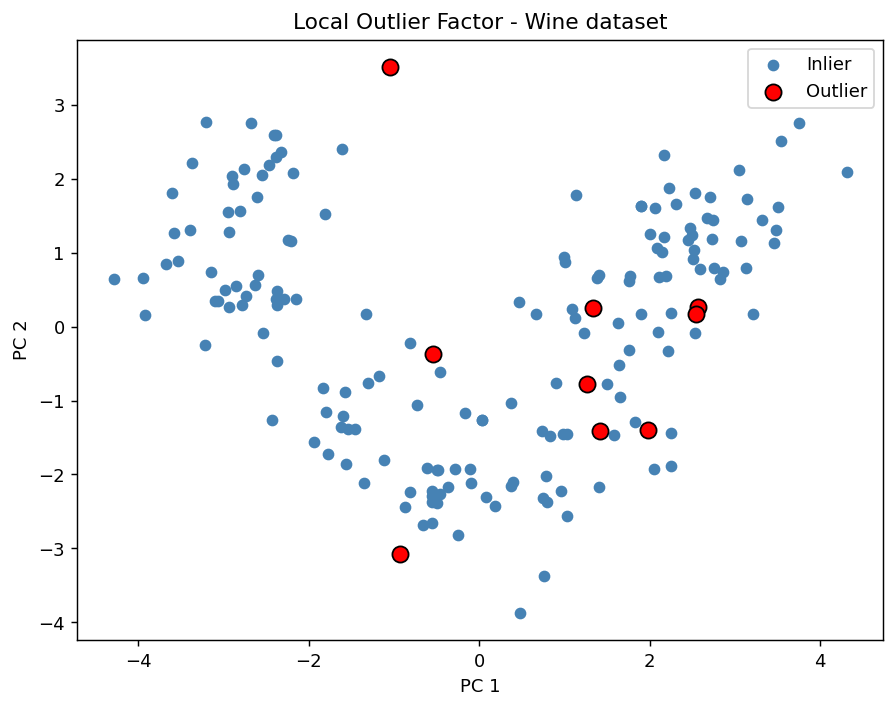

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor

# Numerical dataset: Wine (178 samples, 13 numeric features)
X = load_wine().data
X_scaled = StandardScaler().fit_transform(X)

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
labels = lof.fit_predict(X_scaled)                 # -1 = outlier, 1 = inlier
scores = -lof.negative_outlier_factor_             # higher = more anomalous
print("Total points:", len(X), "| Outliers found:", (labels == -1).sum())
print("Top 5 LOF scores:", np.sort(scores)[-5:].round(2))

# 2D view using PCA
X2 = PCA(n_components=2).fit_transform(X_scaled)
plt.figure(figsize=(8, 6))
plt.scatter(X2[labels == 1, 0], X2[labels == 1, 1], c="steelblue", s=30, label="Inlier")
plt.scatter(X2[labels == -1, 0], X2[labels == -1, 1], c="red", s=80,
            edgecolors="k", label="Outlier")
plt.xlabel("PC 1"); plt.ylabel("PC 2")
plt.title("Local Outlier Factor - Wine dataset")
plt.legend(); plt.show()

**Interpretation**: LOF flagged 9 of 178 wine samples (about 5%, as set by `contamination`) as outliers. They lie at the edges of the PCA plot where local density is lower than that of their neighbours.

### **10. Real-time workflow for a power grid monitoring company (15-minute data: timestamp, region, weather, energy usage)**

**Answer**:

🔹 **1. Data pipeline**: Smart-meter data streams into Kafka (or a cloud queue), is cleaned (missing values, duplicates, unit checks) and stored in a time-series database. Features: lag values (previous 15 min, same time yesterday and last week), rolling mean/std, hour, day of week, holiday flag, temperature, humidity, region.

🔹 **2. Anomaly detection (Isolation Forest / LOF / DBSCAN)**: Main detector is **Isolation Forest**, trained per region on normal history and applied to each new 15-minute window (usage, change from previous interval, deviation from forecast residual). It is fast, scales to many regions, works on streaming micro-batches and needs no distance matrix. **LOF** is slower and needs the whole reference set, so it suits offline investigation of local anomalies. **DBSCAN** needs reclustering, so it is better for offline grouping of anomaly events. Since usage has strong daily seasonality, detection is done on **forecast residuals**, which separates true spikes/drops from normal peak hours. An alert is raised when the anomaly score crosses a threshold and persists for 2 consecutive windows, to cut false alarms.

🔹 **3. Short-term forecasting model**: **SARIMAX**. Demand has daily seasonality (96 intervals per day) and depends on weather such as temperature, which only SARIMAX can take as exogenous input (ARIMA has no seasonality, SARIMA has no external inputs). Steps: ADF test, differencing if needed, orders from ACF/PACF or AIC search, forecast temperature as exogenous input for the next 1 to 24 hours.

🔹 **4. Validation and monitoring**: Use **walk-forward (rolling-origin) validation**, never random splits. Metrics: MAE, RMSE, MAPE versus a naive baseline (same time yesterday). In production track daily forecast error, residual ACF, anomaly rate and score drift; detect **data/concept drift** (new season, new consumers) and retrain weekly or when error crosses a threshold. Operators review flagged anomalies and confirmed labels are used to tune the contamination threshold.

🔹 **5. Business value**: Accurate forecasts support generation scheduling, power purchase planning and load balancing, reducing penalties and peak-price purchases. Early anomaly alerts help detect equipment faults, outages, theft/meter tampering and cyber-attacks so crews respond sooner. Overall: higher reliability, lower cost, better demand-response and capacity planning.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from statsmodels.tsa.statespace.sarimax import SARIMAX

# ---- 1. Simulated 15-minute grid data (replace with real feed) ----
rng = np.random.default_rng(42)
idx = pd.date_range("2025-01-01", periods=96 * 14, freq="15min")        # 14 days
hour = idx.hour + idx.minute / 60
temp = 25 + 8 * np.sin((hour - 9) / 24 * 2 * np.pi) + rng.normal(0, 0.5, len(idx))
usage = 300 + 80 * np.sin((hour - 6) / 24 * 2 * np.pi) + 4 * temp + rng.normal(0, 8, len(idx))
usage[[200, 600, 900]] += [250, -200, 300]                              # injected spikes/drops
data = pd.DataFrame({"usage": usage, "temp": temp}, index=idx)

# ---- 2. Short-term forecasting: SARIMAX with weather as exogenous input ----
train, test = data.iloc[:-96], data.iloc[-96:]                          # forecast last day
model = SARIMAX(train["usage"], exog=train[["temp"]],
                order=(2, 0, 1), seasonal_order=(1, 0, 0, 96))
fit = model.fit(disp=False, maxiter=50)
pred = fit.get_forecast(steps=96, exog=test[["temp"]]).predicted_mean
mape = (abs(test["usage"] - pred) / test["usage"]).mean() * 100
print(f"Next-24h forecast MAPE: {mape:.2f}%")

# ---- 3. Anomaly detection on model residuals + rolling window ----
feat = pd.DataFrame({"resid": fit.resid,
                     "roll_mean": data["usage"].rolling(4).mean().loc[train.index],
                     "diff": data["usage"].diff().loc[train.index]}).dropna()
iso = IsolationForest(contamination=0.005, random_state=42).fit(feat)
feat["anomaly"] = iso.predict(feat)
print("Anomalies flagged:", (feat.anomaly == -1).sum())

# ---- 4. Visualise ----
fig, ax = plt.subplots(2, 1, figsize=(11, 7))
ax[0].plot(test["usage"], label="Actual"); ax[0].plot(pred, "r--", label="Forecast")
ax[0].set_title("Next-day demand forecast (SARIMAX)"); ax[0].legend()
ax[1].plot(data["usage"], lw=0.7)
a = feat[feat.anomaly == -1].index
ax[1].scatter(a, data.loc[a, "usage"], c="red", label="Anomaly")
ax[1].set_title("Detected spikes/drops (Isolation Forest)"); ax[1].legend()
plt.tight_layout(); plt.show()